In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [12]:
def foce_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   

    energies=[]
    n_atom_per_structure=[]
    mean_module_square=[]
    atom_count=0
    struct_count=0
    tmp=0
    for i , line in enumerate(lines):
        
        if line.startswith('atom'):
            split_line=line.split()
            #print(split_line)
            tmp=tmp+  float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2
            
            #print(tmp)
            atom_count=atom_count+1
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
            energies.append(float(split_line[1]))
            mean_module_square.append(tmp/atom_count)
            n_atom_per_structure.append(atom_count)
            struct_count=struct_count+1
            
            atom_count=0 
            tmp=0
    print(struct_count)
            
       
            
        
    
    return energies, mean_module_square, n_atom_per_structure

In [13]:
dataset_file='./new_clean.data'
energies, mean_force, n_atom=foce_analysis(dataset_file)




6318


In [14]:
#print(n_atom)

list_atom_number=np.sort(list(set(n_atom)))

print(list_atom_number)

[111 114 126 132 138 144 150 156 162 186 210 234 312 384]


In [15]:
n_ordered_input_index=[]
for i, n in enumerate(list_atom_number):
    n_ordered_input_index.append(np.where(np.array(n_atom) == n)[0])
    print(len(n_ordered_input_index[i]))

170
1543
189
317
792
466
732
469
285
123
286
269
665
12


In [16]:
n_ordered_energies=[]
n_ordered_forces=[]
n_ordered_energies_atom=[]
for i, n in enumerate(list_atom_number):
    n_ordered_energies.append(np.array(energies)[n_ordered_input_index[i]] )  
    n_ordered_forces.append(np.array(mean_force)[n_ordered_input_index[i]] )
    n_ordered_energies_atom.append(  np.array(energies)[n_ordered_input_index[i]]/ list_atom_number[i] )

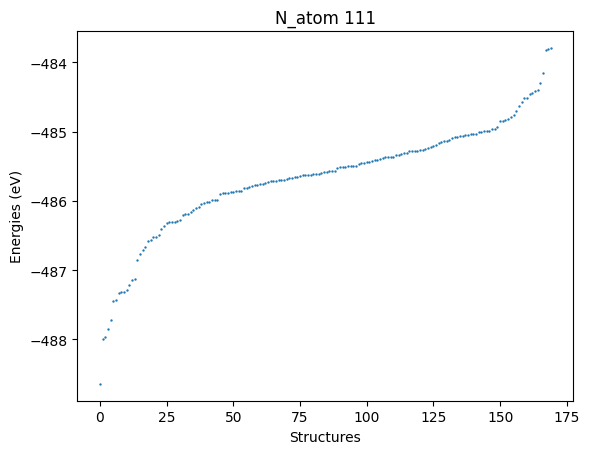

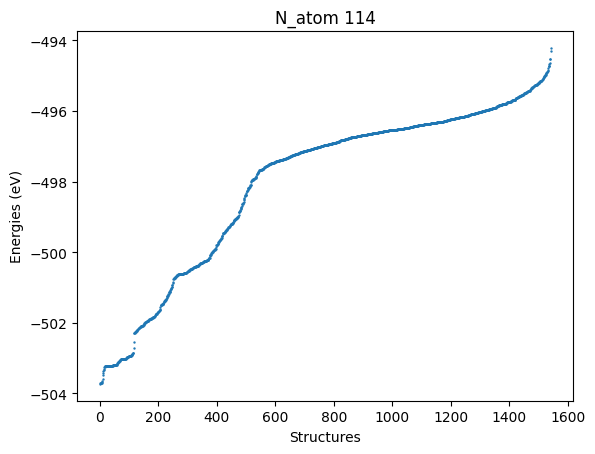

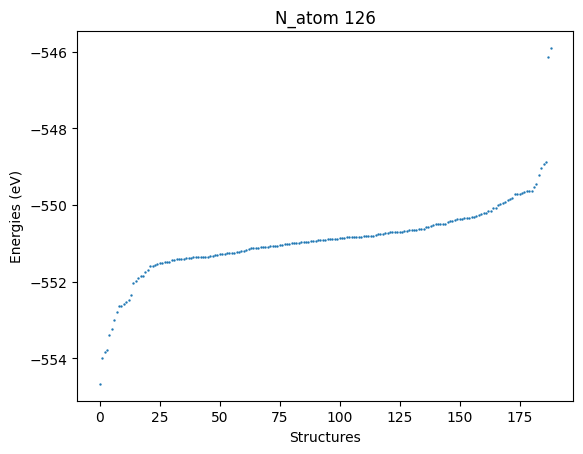

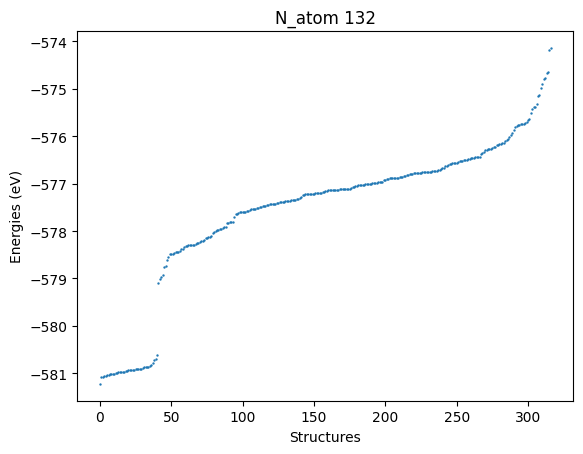

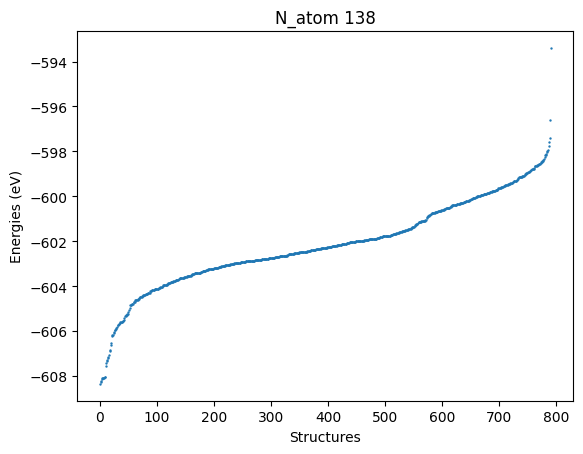

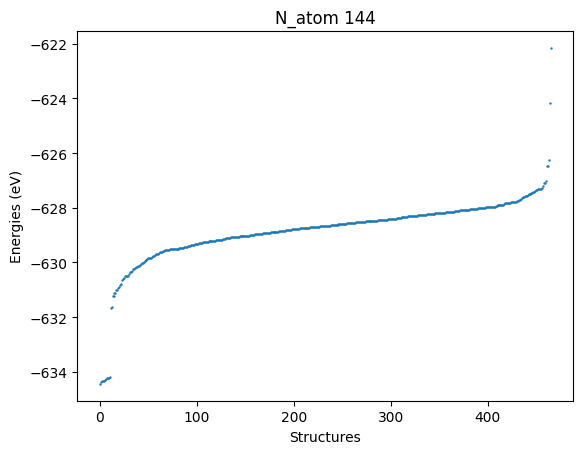

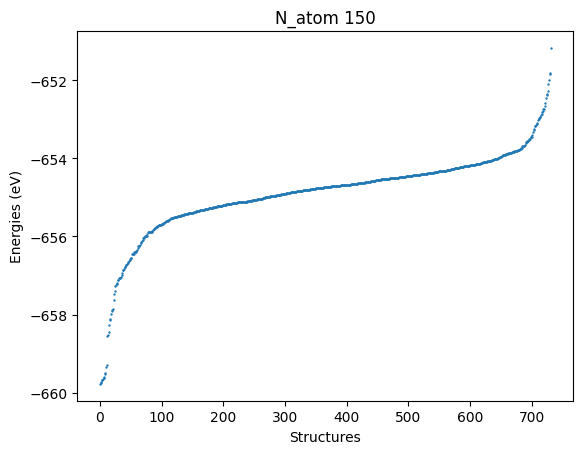

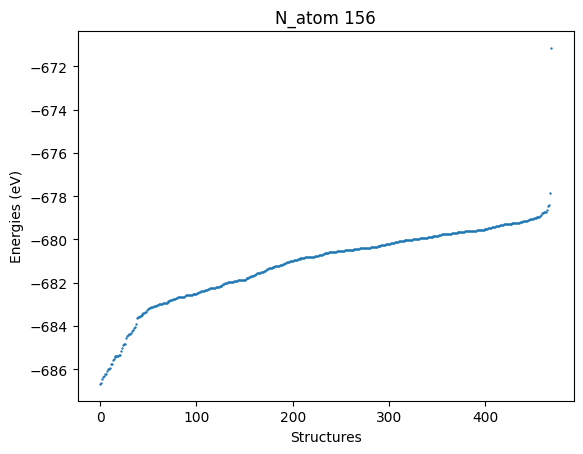

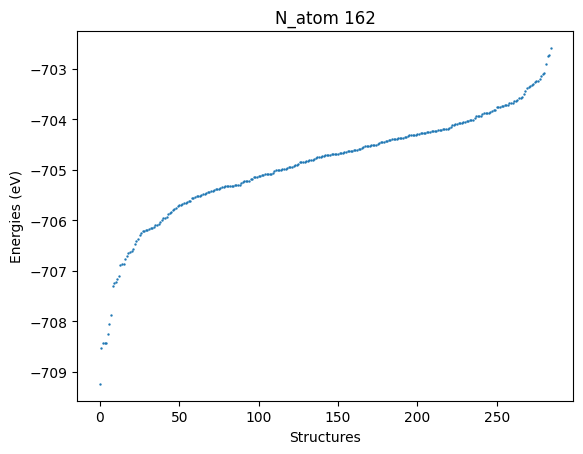

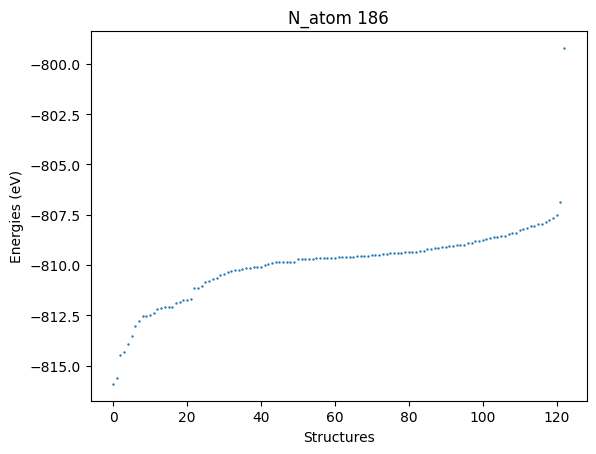

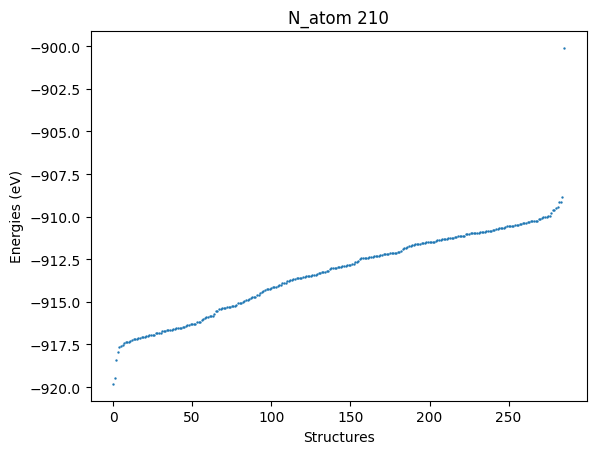

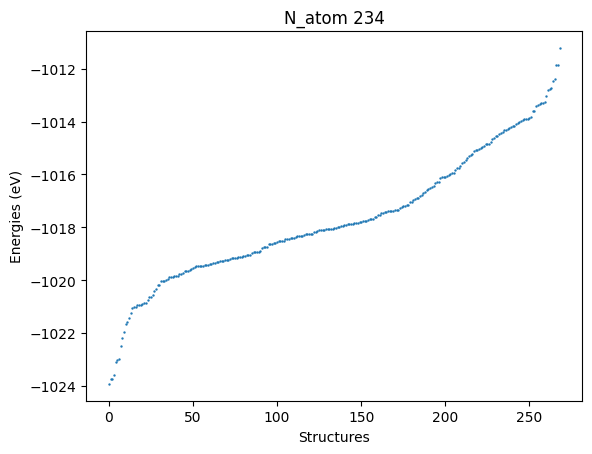

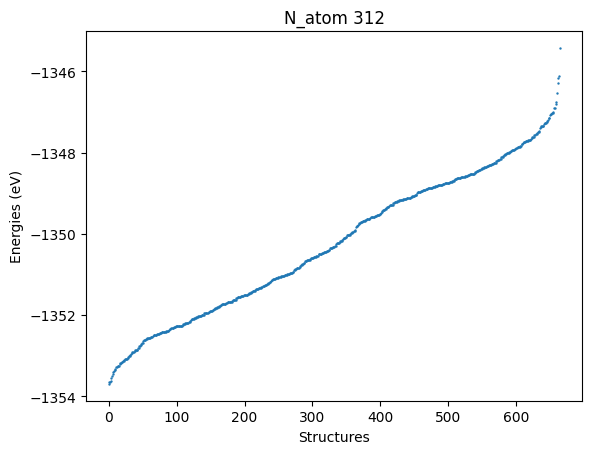

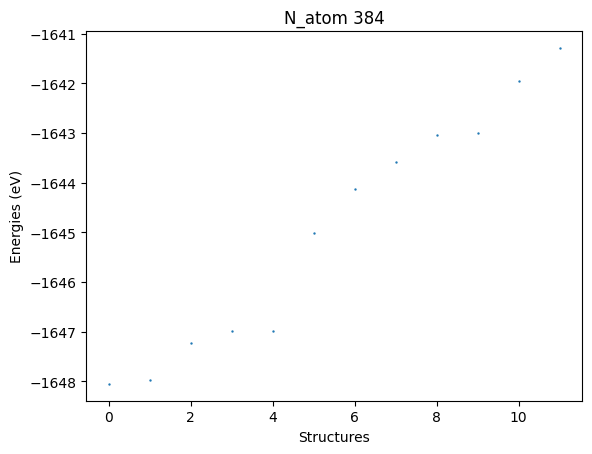

In [17]:
for i, n in enumerate(list_atom_number):
    plt.figure(i+1)
    plt.scatter(np.arange(len(n_ordered_forces[i])),np.sort(n_ordered_energies[i]), s = 0.5)
    plt.xlabel("Structures")
    plt.ylabel("Energies (eV)")
    plt.title('N_atom {}'.format(n))
    #plt.savefig('/data/home/salvatorer26/Desktop/group_meeting/pres_6/start_{}.png'.format(n))

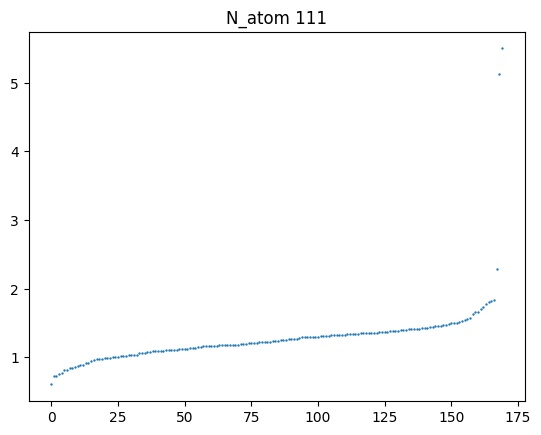

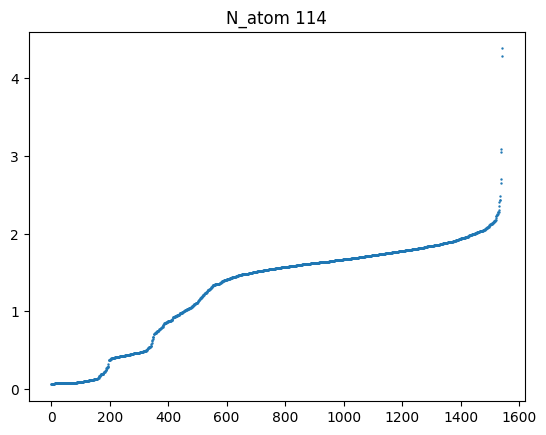

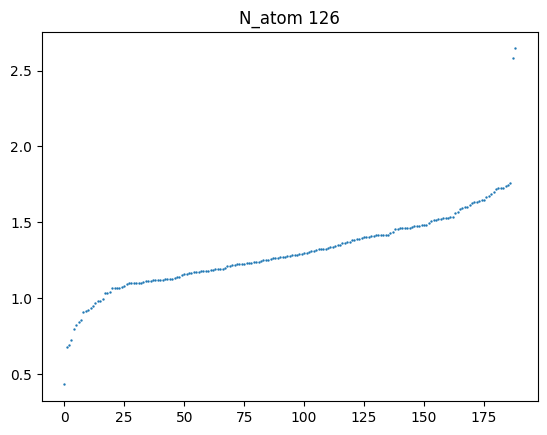

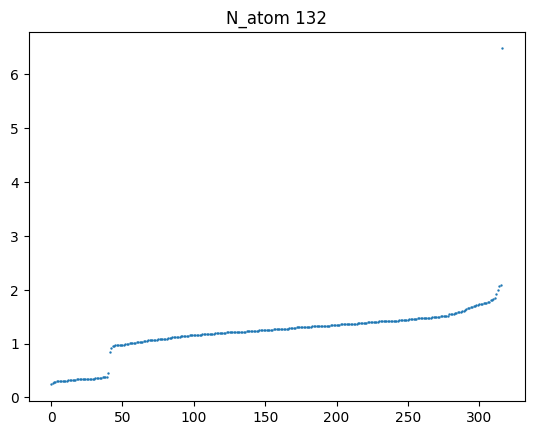

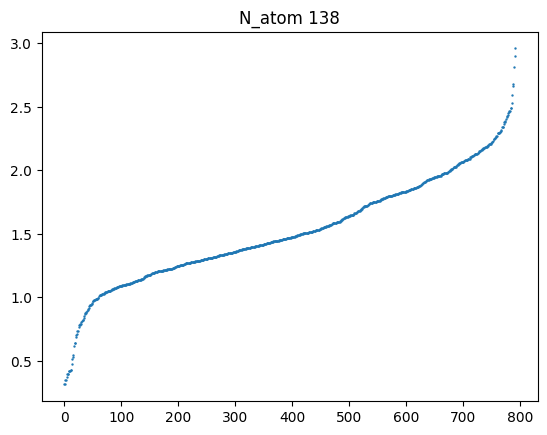

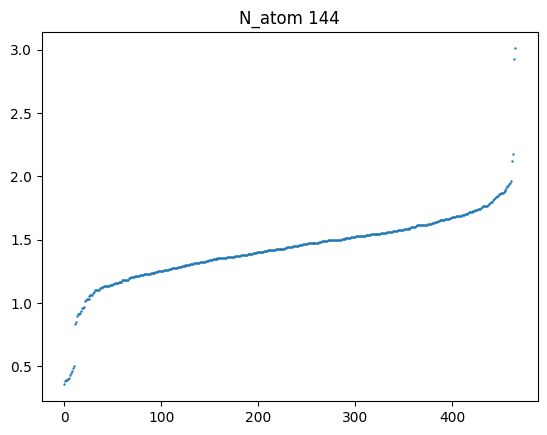

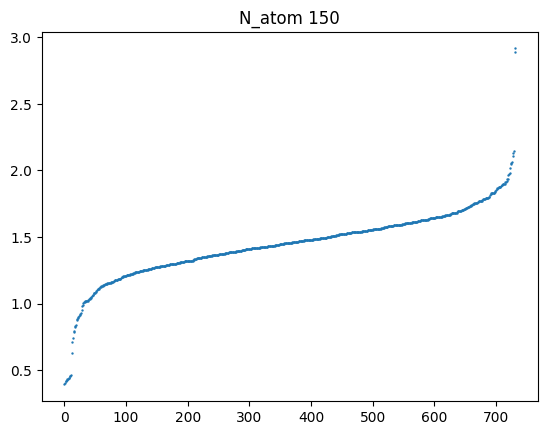

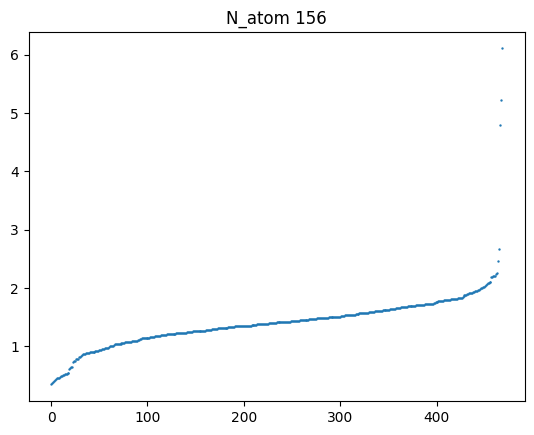

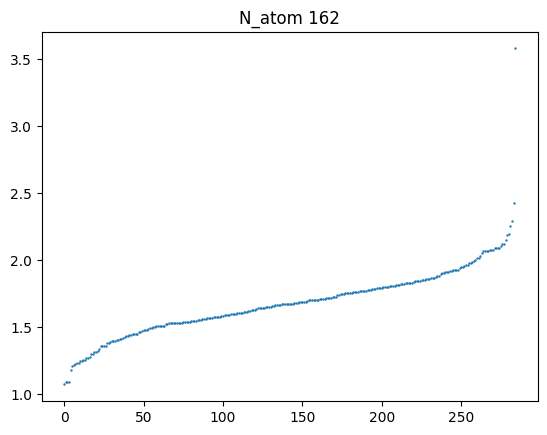

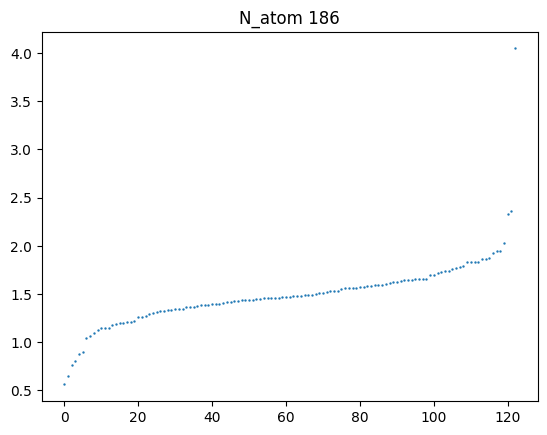

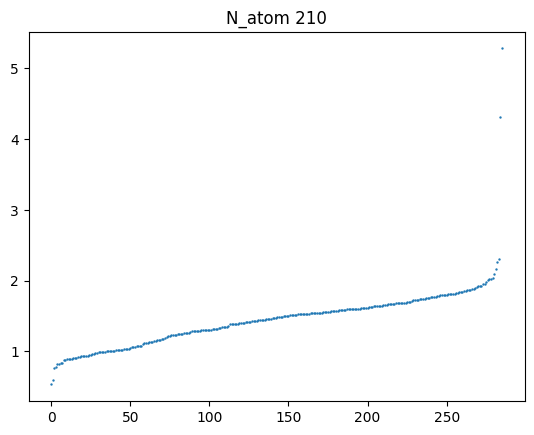

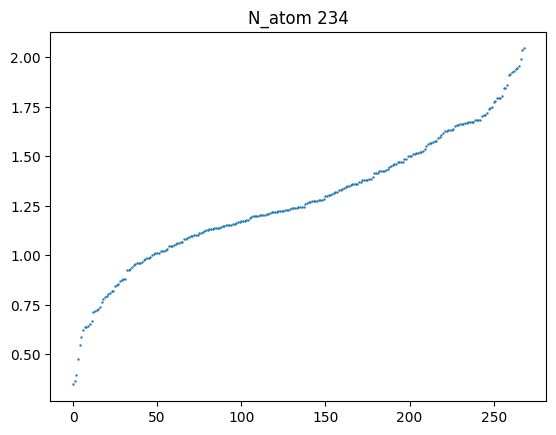

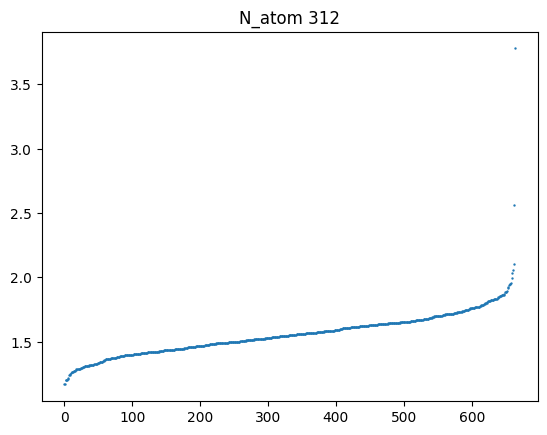

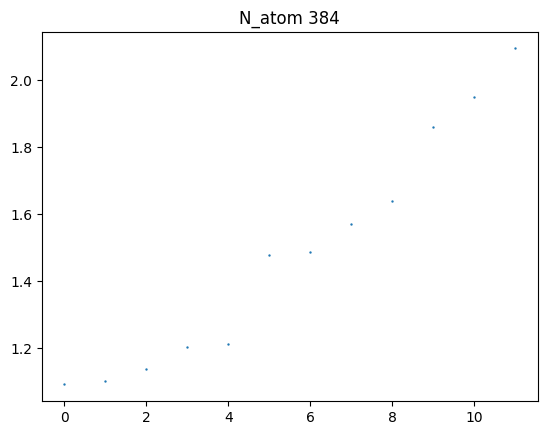

In [19]:
for i, n in enumerate(list_atom_number):
    plt.figure(i+1)
    plt.scatter(np.arange(len(n_ordered_energies[i])),np.sort(n_ordered_forces[i]), s = 0.5)
    
    plt.title('N_atom {}'.format(n))

In [20]:
def print_configurations(dataset_file, structures, good_input_data, control):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
    struct_count=0
    not_count=0   
    #print(index)
    with open(good_input_data, 'w') as new_file:
        index=0
        
        for i, line in enumerate(lines):
            if line.startswith('begin'): 
                if index in structures:
                    if control:
                        bool=True
                    else:
                        bool=False
                    struct_count+=1
                else: 
                    if control:
                        bool=False
                    else:
                        bool=True
                    not_count += 1
                index += 1
            if bool:
                new_file.write(line)
    print("old lenght:", index)    
    print(" str lenght:",struct_count )       
    if control:
        print("new lenght:",struct_count) 
    else:
        print("new lenght:",not_count) 
        
    
    return 

In [22]:
for i , n in enumerate(list_atom_number):
    structure_list=   n_ordered_input_index[i] #list of structure indices (containing zero structure) or if file.txt np.loadtxt("name of file txt")
    new_input_data="input_{}.data".format(n)                            #name of the output file 
    control= True   #set True to print the structures in structure_list, False to print all except from those
    print_configurations(dataset_file, structure_list, new_input_data, control)

old lenght: 6318
 str lenght: 170
new lenght: 170
old lenght: 6318
 str lenght: 1543
new lenght: 1543
old lenght: 6318
 str lenght: 189
new lenght: 189
old lenght: 6318
 str lenght: 317
new lenght: 317
old lenght: 6318
 str lenght: 792
new lenght: 792
old lenght: 6318
 str lenght: 466
new lenght: 466
old lenght: 6318
 str lenght: 732
new lenght: 732
old lenght: 6318
 str lenght: 469
new lenght: 469
old lenght: 6318
 str lenght: 285
new lenght: 285
old lenght: 6318
 str lenght: 123
new lenght: 123
old lenght: 6318
 str lenght: 286
new lenght: 286
old lenght: 6318
 str lenght: 269
new lenght: 269
old lenght: 6318
 str lenght: 665
new lenght: 665
old lenght: 6318
 str lenght: 12
new lenght: 12
